In [1]:
# Projeto: Segmentação de clientes com análise RFM

# O que é análise RFM?

# - RFM é uma técnica utilizada para segmentar clientes com base em três indicadores:

# R = Recency (Recência):
# Há quantos dias o cliente realizou sua última compra?

# F = Frequency (Frequência):
# Quantas compras o cliente realizou?

# M = Monetary (Valor Monetário):
# Quanto dinheiro o cliente gastou?



In [2]:
# Objetivo do projeto:

# 1 - Importar a base de dados;
# 2 - Explorar os dados com Pandas;
# 3 - Tratar valores ausentes e duplicados;
# 4 - Calcular R, F e M;
# 5 - Criar pontuações de 1 a 5;
# 6 - Segmentar os clientes;
# 7 - Criar gráficos e interpretações;
# 8 - Apresentar recomendações de negócio.


In [3]:
# 1 - Importar as bases de dados:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Teste: criando uma base fictícia:
# Reprodutibilidade dos dados:
np.random.seed(42) # Garante que os dados aleatórios possam ser reproduzidos.

# Quantidade de compras:
total_compras = 500

# Identificação dos clientes:
clientes = np.arange(1001, 1121) # Cria uma sequência de números.

# Alguns clientes compram com mais frequência:
pesos = np.arange(1, 121)
pesos = pesos / pesos.sum()

# Gerando os dados:
dados = {
    "InvoiceNo": [
        f"INV{i:04d}" for i in
        range(1, total_compras + 1)
            ],

    "CustomerID": np.random.choice(     # Escolhe valores aleatoriamente.
        clientes,
        size=total_compras,
        p=pesos
    ),

    "InvoiceDate": np.random.choice(
        pd.date_range("2025-01-01",
        "2025-12-31"),
        size=total_compras
    ),

    "Quantity": np.random.randint(1,
    10, total_compras),

    "UnitPrice": np.random.choice(
        [10, 15, 20, 25, 30, 40, 50, 75, 100],
        size=total_compras
    )
}

# Criando o DataFrame:
df = pd.DataFrame(dados)

# Exportando para CSV:
df.to_csv("vendas_ficticias.csv",
index=False)

print("Base de dados criada com sucesso!")
print(df.head())


Base de dados criada com sucesso!
  InvoiceNo  CustomerID InvoiceDate  Quantity  UnitPrice
0   INV0001        1074  2025-05-25         7         10
1   INV0002        1117  2025-07-20         1         25
2   INV0003        1103  2025-07-31         4         40
3   INV0004        1093  2025-08-08         9         50
4   INV0005        1048  2025-08-28         1         15


In [5]:
# 2 - Explorar os dados com Pandas (Análise exploratória - EDA)

# Carregar a base
df = pd.read_csv("vendas_ficticias.csv")

# Visualizando as primeiras linhas:
print(df.head()) # Visualiza as primeiras linhas.

# Verificando a quantidade de linhas e colunas:
print(df.shape) # Identifica as dimensões da base.

# Informações sobre as colunas:
print(df.info()) # Verifica os tipos de dados e preenchimento.

# Estatísticas descritivas:
print(df.describe()) # Obter estatísticas descritivas.

# Verificando valores ausentes:
print(df.isnull().sum()) # Conta valores ausentes por colunas.


  InvoiceNo  CustomerID InvoiceDate  Quantity  UnitPrice
0   INV0001        1074  2025-05-25         7         10
1   INV0002        1117  2025-07-20         1         25
2   INV0003        1103  2025-07-31         4         40
3   INV0004        1093  2025-08-08         9         50
4   INV0005        1048  2025-08-28         1         15
(500, 5)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   InvoiceNo    500 non-null    str  
 1   CustomerID   500 non-null    int64
 2   InvoiceDate  500 non-null    str  
 3   Quantity     500 non-null    int64
 4   UnitPrice    500 non-null    int64
dtypes: int64(3), str(2)
memory usage: 19.7 KB
None
        CustomerID    Quantity   UnitPrice
count   500.000000  500.000000  500.000000
mean   1079.748000    4.920000   39.840000
std      29.704566    2.669054   27.993601
min    1009.000000    1.000000   10.000000
25%    10

In [6]:
# Ao observar os dados da EDA, começamos o tratamento:

# Convertendo a coluna de datas:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"]) # Converte uma coluna para o formato de data e hora.

# Verificando os registros duplicados:
print("Duplicados:", df.duplicated().sum()) # Conta quantas linhas estão completamente duplicadas.

# Criando uma coluna de faturamento:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"] # Cria uma nova coluna chamada TotalPrice.

# Visualizando os resultados:
print(df.head())

# Verificando novamente os tipos de dados:
print(df.dtypes)


Duplicados: 0
  InvoiceNo  CustomerID InvoiceDate  Quantity  UnitPrice  TotalPrice
0   INV0001        1074  2025-05-25         7         10          70
1   INV0002        1117  2025-07-20         1         25          25
2   INV0003        1103  2025-07-31         4         40         160
3   INV0004        1093  2025-08-08         9         50         450
4   INV0005        1048  2025-08-28         1         15          15
InvoiceNo                 str
CustomerID              int64
InvoiceDate    datetime64[us]
Quantity                int64
UnitPrice               int64
TotalPrice              int64
dtype: object


In [7]:
# Agrupando os dados por cliente (calculando Frequency (F) e Monetary (M)):
analise_clientes =  df.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "count"),
    Monetary=("TotalPrice", "sum")
)

# Visualizando os resultados:
print(analise_clientes.head(10))

            Frequency  Monetary
CustomerID                     
1009                2       975
1010                1       600
1012                1       900
1013                3       960
1014                1       900
1015                1        15
1016                2       655
1017                1        70
1018                1        15
1019                3       695


In [8]:
# Identificando a data mais recente da base para calcular a Recency (R):
# Definindo uma data de referência: vou utilizar o dia seguinte à última compra registrada.
data_referencia = df["InvoiceDate"].max() + pd.Timedelta(days=1) # max() encontra a maior data da coluna, e pd.Timedelta(days=1) acrescenta um dia.

print("Data de referência:", data_referencia)

Data de referência: 2026-01-01 00:00:00


In [9]:
# Calculando a última compra de cada cliente:
# Encontrando a última compra de cada cliente:
ultima_compra = df.groupby("CustomerID").agg(
    LastPurchaseDate=("InvoiceDate", "max")
)

# Calculando a Recency:
ultima_compra["Recency"] = (data_referencia - ultima_compra["LastPurchaseDate"]).dt.days

print(ultima_compra.head(10))

           LastPurchaseDate  Recency
CustomerID                          
1009             2025-08-24      130
1010             2025-07-03      182
1012             2025-07-21      164
1013             2025-11-20       42
1014             2025-11-24       38
1015             2025-03-11      296
1016             2025-10-19       74
1017             2025-07-16      169
1018             2025-06-06      209
1019             2025-12-01       31


In [10]:
# Unindo as métricas R, F e M
rfm = analise_clientes.join(ultima_compra)

print(rfm.head(10))

            Frequency  Monetary LastPurchaseDate  Recency
CustomerID                                               
1009                2       975       2025-08-24      130
1010                1       600       2025-07-03      182
1012                1       900       2025-07-21      164
1013                3       960       2025-11-20       42
1014                1       900       2025-11-24       38
1015                1        15       2025-03-11      296
1016                2       655       2025-10-19       74
1017                1        70       2025-07-16      169
1018                1        15       2025-06-06      209
1019                3       695       2025-12-01       31


In [11]:
# R_Score: pontuação de recência.
# F_Score: pontuação de frequência.
# M_Score: pontuação monetária.

# A lógica será:
# Recency: quanto menos dias sem comprar, maior a nota.
# Frequency: quanto mais compras, maior a nota.
# Monetary: quanto maior o gasto, maior a nota.

# Criando as pontuações RFM:

rfm["R_Score"] = pd.qcut(

rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(

rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(

rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

print(rfm.head(10))

# O que é o pd.qcut()?
# - É uma função do Pandas que divide os dados em grupos com quantidades aproximadamente iguais de registros.
# Exemplo: podemos dividir os clientes em cinco grupos:
# Grupo ----------> Pontuação
# 20% melhores ---> 5
# Próximos 20% ---> 4
# Próximos 20% ---> 3
# Próximos 20% ---> 2
# 20% inferiores -> 1

# O rank(method="first") ajuda a lidar com valores repetidos antes da divisão em grupos.

            Frequency  Monetary LastPurchaseDate  Recency  R_Score  F_Score  \
CustomerID                                                                    
1009                2       975       2025-08-24      130        1        1   
1010                1       600       2025-07-03      182        1        1   
1012                1       900       2025-07-21      164        1        1   
1013                3       960       2025-11-20       42        4        2   
1014                1       900       2025-11-24       38        4        1   
1015                1        15       2025-03-11      296        1        1   
1016                2       655       2025-10-19       74        2        1   
1017                1        70       2025-07-16      169        1        1   
1018                1        15       2025-06-06      209        1        1   
1019                3       695       2025-12-01       31        4        2   

            M_Score  
CustomerID           
1009   

In [12]:
# Construindo o RFM Score:
# Criando a pontuação RFM combinada:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) + 
    rfm["F_Score"].astype(str) + 
    rfm["M_Score"].astype(str)
)

# Visualizando o resultado
print(
    rfm[
        ["Recency", "Frequency", "Monetary",
        "R_Score", "F_Score", "M_Score", "RFM_Score"]
    ].head(10)
)


            Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
CustomerID                                                                   
1009            130          2       975        1        1        4       114
1010            182          1       600        1        1        2       112
1012            164          1       900        1        1        3       113
1013             42          3       960        4        2        4       424
1014             38          1       900        4        1        3       413
1015            296          1        15        1        1        1       111
1016             74          2       655        2        1        3       213
1017            169          1        70        1        1        1       111
1018            209          1        15        1        1        1       111
1019             31          3       695        4        2        3       423


In [13]:
# Segmentação dos clientes:
# Segmento ------> Critério:
# Campeões ------> R, F e M maiores ou iguais a 4
# Fiéis ---------> F maior ou igual a 4 e R maior ou igual a 3
# Recentes ------> R maior ou igual a 4 e F menor ou igual a 2
# Em risco ------> R menor ou igual a 2 e F maior ou igual a 3
# Outros --------> Clientes que não se encaixam nas regras anteriores

# Definindo as condições de segmentação:

condicoes = [
    (
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 4) &
        (rfm["M_Score"] >= 4)
    ),

    (
        (rfm["F_Score"] >= 4) &
        (rfm["R_Score"] >= 3)
    ),

    (
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] <= 2)
    ),

    (
        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] >= 3)
    )
]

# Definindo os nomes dos segmentos:

segmentos = [
    "Campeões",
    "Fiéis",
    "Recentes",
    "Em risco"
]

# Aplicando a segmentação:

rfm["Segmento"] = np.select( # Verifica as condições e atribui os segmentos.
    condicoes,
    segmentos,
    default="Outros" # Classifica quem não atende às condições anteriores.
)

# Visualizando os resultados:
print(rfm[["RFM_Score",
"Segmento"]].head(15))

# Quantidade de clientes em cada segmento:
print(rfm["Segmento"].value_counts())

# Percentual de clientes em cada segmento:
print(
    rfm["Segmento"].value_counts(normalize=True).mul(100).round(2)
)

# normalize=True: transforma a contagem absoluta em proporções entre 0 e 1. Por exemplo, se metade dos clientes está em um grupo, o resultado será 0.5 em vez da quantidade exata de clientes.

# .mul(100): multiplica essas proporções por 100 para transformá-las em porcentagem. O valor 0.5, por exemplo, passa a ser 50.0.

# .round(2): arredonda os valores para, no máximo, duas casas decimais, deixando a leitura mais limpa (ex.: 33.33 em vez de 33.333333).

           RFM_Score  Segmento
CustomerID                    
1009             114    Outros
1010             112    Outros
1012             113    Outros
1013             424  Recentes
1014             413  Recentes
1015             111    Outros
1016             213    Outros
1017             111    Outros
1018             111    Outros
1019             423  Recentes
1020             213    Outros
1021             211    Outros
1022             112    Outros
1023             422  Recentes
1024             111    Outros
Segmento
Outros      45
Campeões    20
Em risco    17
Fiéis       15
Recentes    10
Name: count, dtype: int64
Segmento
Outros      42.06
Campeões    18.69
Em risco    15.89
Fiéis       14.02
Recentes     9.35
Name: proportion, dtype: float64


In [14]:
# Análise financeira por segmento:

resumo_segmentos = rfm.groupby("Segmento").agg(
    Quantidade_Clientes=("Monetary", "count"),
    Faturamento_Total=("Monetary", "sum"),
    Ticket_Medio=("Monetary", "mean"),
    Frequencia_Media=("Frequency", "mean"),
    Recencia_Media=("Recency", "mean")
)

print(resumo_segmentos.round(2))

          Quantidade_Clientes  Faturamento_Total  Ticket_Medio  \
Segmento                                                         
Campeões                   20              32715       1635.75   
Em risco                   17              18585       1093.24   
Fiéis                      15              18550       1236.67   
Outros                     45              19700        437.78   
Recentes                   10               7345        734.50   

          Frequencia_Media  Recencia_Media  
Segmento                                    
Campeões              7.90           14.70  
Em risco              5.53          114.65  
Fiéis                 7.40           43.67  
Outros                2.47          109.67  
Recentes              2.60           35.90  


In [15]:
# Calculando o ticket médio por compra:

resumo_segmentos["Ticket_Medio_Compra"] = (

resumo_segmentos["Faturamento_Total"]
 /
    rfm.groupby("Segmento")
["Frequency"].sum()
)

print(
    resumo_segmentos[
        ["Faturamento_Total",
    "Ticket_Medio_Compra"]
    ].round(2)
)

          Faturamento_Total  Ticket_Medio_Compra
Segmento                                        
Campeões              32715               207.06
Em risco              18585               197.71
Fiéis                 18550               167.12
Outros                19700               177.48
Recentes               7345               282.50


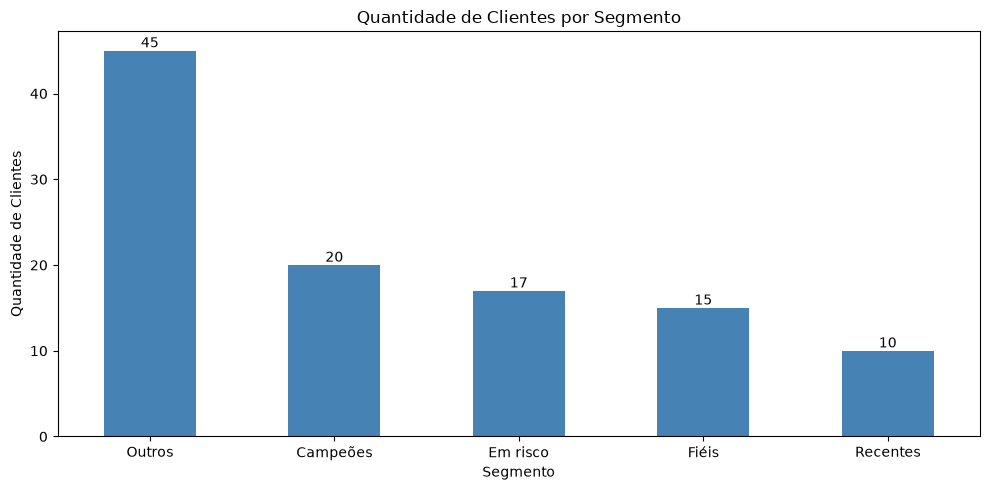

In [16]:
# Quantidade de clientes por segmento:
clientes_segmento = rfm["Segmento"].value_counts() # Conta quantos clientes existem em cada segmento.

plt.figure(figsize=(10, 5)) # Define o tamanho do gráfico.

clientes_segmento.plot(
    kind="bar", # Cria um gráfico de barras.
    color="steelblue"
)

grafico = plt.gca()

for barra in grafico.patches:
    altura = barra.get_height()

    grafico.annotate(
        str(int(altura)),
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom"
    )

plt.title("Quantidade de Clientes por Segmento") # title, xlabel e ylabel definem o título e os nomes dos eixos.
plt.xlabel("Segmento")
plt.ylabel("Quantidade de Clientes")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show() # Exibe o resultado.

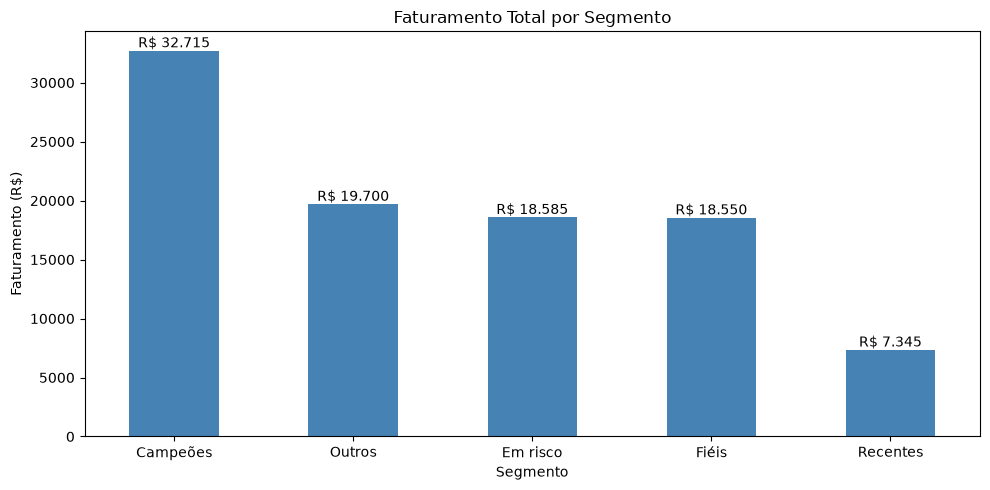

In [17]:
# Faturamento total por segmento:
faturamento_segmento = (
    rfm.groupby("Segmento")["Monetary"]
    .sum()
    .sort_values(ascending=False) # Organiza do maior para o menor faturamento.
)

plt.figure(figsize=(10, 5))

grafico = faturamento_segmento.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Faturamento Total por Segmento")
plt.xlabel("Segmento")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)

# Adicionando os valores sobre as barras:
for barra in grafico.patches:
    altura = barra.get_height()

    valor = f"R$ {altura:,.0f}".replace(",", ".")

    grafico.annotate(
        valor,
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

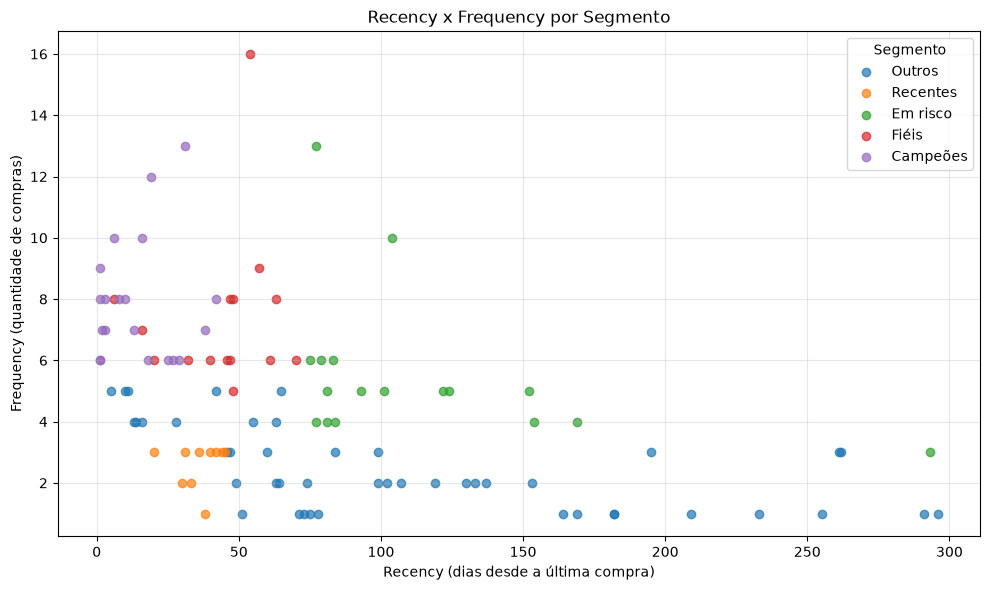

In [18]:
# Relação entre Recency e Frequency:

plt.figure(figsize=(10, 6))

for segmento in rfm["Segmento"].unique(): # Percorre cada segmento existente na nossa base.

    dados_segmento = rfm[rfm["Segmento"] == segmento] # Filtra somente os clientes daquele segmento.

    plt.scatter( # Desenha os pontos no gráfico.
        dados_segmento["Recency"],
        dados_segmento["Frequency"],
        label=segmento,
        alpha=0.7
    )

plt.title("Recency x Frequency por Segmento")
plt.xlabel("Recency (dias desde a última compra)")
plt.ylabel("Frequency (quantidade de compras)")

plt.legend(title="Segmento")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

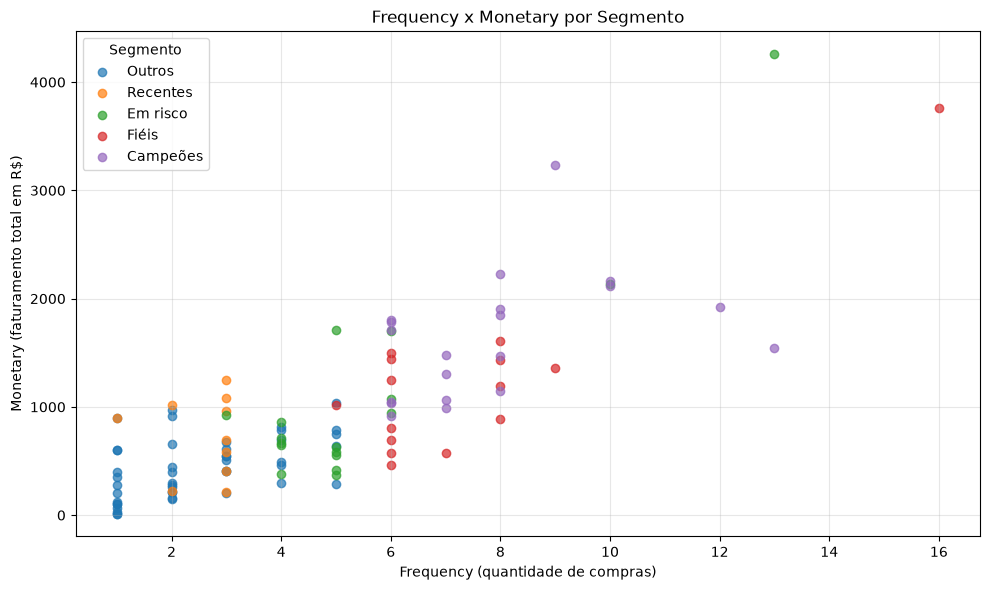

In [19]:
# Relação entre Frequency e Monetary:

plt.figure(figsize=(10, 6))

for segmento in rfm["Segmento"].unique():

    dados_segmento = rfm[rfm["Segmento"] == segmento]

    plt.scatter(
        dados_segmento["Frequency"],
        dados_segmento["Monetary"],
        label=segmento,
        alpha=0.7
    )

plt.title("Frequency x Monetary por Segmento")
plt.xlabel("Frequency (quantidade de compras)")
plt.ylabel("Monetary (faturamento total em R$)")

plt.legend(title="Segmento")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()